In [1]:
import pandas as pd

tx = pd.read_csv("quickcart_basket_transactions.csv")

print(tx.head())
print(tx.shape)
print(tx.info())

    order_id        date store_id  sku_id            sku_name  \
0  ORD-00001  2026-11-05     ST02  SKU025           Rusk 200g   
1  ORD-00001  2026-11-05     ST02  SKU055    White Bread 400g   
2  ORD-00001  2026-11-05     ST02  SKU009       Capsicum 500g   
3  ORD-00001  2026-11-05     ST02  SKU010       Toned Milk 1L   
4  ORD-00001  2026-11-05     ST02  SKU029  Energy Drink 250ml   

              category  
0               Snacks  
1               Bakery  
2  Fruits & Vegetables  
3                Dairy  
4            Beverages  
(26878, 6)
<class 'pandas.DataFrame'>
RangeIndex: 26878 entries, 0 to 26877
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   order_id  26878 non-null  str  
 1   date      26878 non-null  str  
 2   store_id  26878 non-null  str  
 3   sku_id    26878 non-null  str  
 4   sku_name  26878 non-null  str  
 5   category  26878 non-null  str  
dtypes: str(6)
memory usage: 2.6 MB
None


In [2]:
print("Total orders:", tx["order_id"].nunique())

print("Total unique products:", tx["sku_id"].nunique())

print("Total stores:", tx["store_id"].nunique())

print("\nTop 10 most frequently appearing products:")
print(tx["sku_name"].value_counts().head(10))

Total orders: 5000
Total unique products: 60
Total stores: 12

Top 10 most frequently appearing products:
sku_name
White Bread 400g       1273
Toned Milk 1L          1270
Potato Chips 90g       1092
Cola 750ml             1082
Toor Dal 1kg           1034
Cooking Oil 1L          998
Basmati Rice 5kg        991
Choco Cookies 150g      888
Instant Coffee 100g     885
Ghee 500ml              853
Name: count, dtype: int64


In [3]:
#shopping basket matrix
basket = tx.pivot_table(
    index="order_id",
    columns="sku_name",
    values="sku_id",
    aggfunc="count",
    fill_value=0
)

basket = (basket > 0).astype(int)

print(basket.head())
print("\nBasket shape:", basket.shape)

sku_name   Air Freshener  Apple 1kg  Banana 1kg  Banana Chips 150g  \
order_id                                                             
ORD-00001              0          0           0                  0   
ORD-00002              0          0           0                  0   
ORD-00003              0          0           0                  0   
ORD-00004              0          0           0                  0   
ORD-00005              0          0           0                  0   

sku_name   Bar Soap 125g  Basmati Rice 5kg  Besan 1kg  Brown Bread 400g  \
order_id                                                                  
ORD-00001              0                 0          0                 0   
ORD-00002              0                 1          0                 0   
ORD-00003              1                 0          0                 0   
ORD-00004              0                 0          0                 0   
ORD-00005              0                 0          0      

In [4]:
%pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
#Apriori algorithm
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    basket,
    min_support=0.02,
    use_colnames=True
)

print("Total frequent itemsets:", len(frequent_itemsets))
print(frequent_itemsets.head(10))

C:\Users\pankaj kumar\AppData\Roaming\Python\Python314\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Total frequent itemsets: 256
   support                        itemsets
0   0.0568      frozenset({Air Freshener})
1   0.0608          frozenset({Apple 1kg})
2   0.0600         frozenset({Banana 1kg})
3   0.0578  frozenset({Banana Chips 150g})
4   0.0604      frozenset({Bar Soap 125g})
5   0.1982   frozenset({Basmati Rice 5kg})
6   0.0668          frozenset({Besan 1kg})
7   0.0588   frozenset({Brown Bread 400g})
8   0.0626        frozenset({Butter 100g})
9   0.0670      frozenset({Buttermilk 1L})


In [7]:
from mlxtend.frequent_patterns import apriori, fpgrowth

basket_bool = basket.astype(bool)

frequent_itemsets = apriori(
    basket_bool,
    min_support=0.02,
    use_colnames=True
)

print("Apriori itemsets:", len(frequent_itemsets))

frequent_itemsets_fp = fpgrowth(
    basket_bool,
    min_support=0.02,
    use_colnames=True
)

print("FP-Growth itemsets:", len(frequent_itemsets_fp))

Apriori itemsets: 256
FP-Growth itemsets: 256


In [8]:
#association rules
from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.3
)

print("Total association rules:", len(rules))

print(
    rules[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(10).to_string(index=False)
)

Total association rules: 456
                     antecedents                      consequents  support  confidence     lift
     frozenset({Cooking Oil 1L})    frozenset({Basmati Rice 5kg})   0.1462    0.732465 3.695585
   frozenset({Basmati Rice 5kg})      frozenset({Cooking Oil 1L})   0.1462    0.737639 3.695585
   frozenset({Basmati Rice 5kg})        frozenset({Toor Dal 1kg})   0.1534    0.773966 3.742581
       frozenset({Toor Dal 1kg})    frozenset({Basmati Rice 5kg})   0.1534    0.741779 3.742581
frozenset({Instant Coffee 100g})  frozenset({Choco Cookies 150g})   0.1520    0.858757 4.835344
 frozenset({Choco Cookies 150g}) frozenset({Instant Coffee 100g})   0.1520    0.855856 4.835344
   frozenset({Potato Chips 90g})          frozenset({Cola 750ml})   0.1974    0.903846 4.176738
         frozenset({Cola 750ml})    frozenset({Potato Chips 90g})   0.1974    0.912200 4.176738
     frozenset({Cooking Oil 1L})        frozenset({Toor Dal 1kg})   0.1544    0.773547 3.740557
       froz

In [9]:
#strongest rules in all 456 rules
top_rules = rules.sort_values(
    by="lift",
    ascending=False
)

print(
    top_rules[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(10).to_string(index=False)
)

                                           antecedents                                            consequents  support  confidence      lift
      frozenset({Choco Cookies 150g, Face Wash 100ml}) frozenset({Instant Coffee 100g, Hand Sanitizer 200ml})   0.0206    0.751825 26.850886
frozenset({Instant Coffee 100g, Hand Sanitizer 200ml})       frozenset({Choco Cookies 150g, Face Wash 100ml})   0.0206    0.735714 26.850886
     frozenset({Instant Coffee 100g, Face Wash 100ml})  frozenset({Choco Cookies 150g, Hand Sanitizer 200ml})   0.0206    0.741007 26.848087
 frozenset({Choco Cookies 150g, Hand Sanitizer 200ml})      frozenset({Instant Coffee 100g, Face Wash 100ml})   0.0206    0.746377 26.848087
            frozenset({Choco Cookies 150g, Poha 500g})           frozenset({Instant Coffee 100g, Ghee 500ml})   0.0234    0.774834 26.001156
          frozenset({Instant Coffee 100g, Ghee 500ml})             frozenset({Choco Cookies 150g, Poha 500g})   0.0234    0.785235 26.001156
           fr

In [10]:
#Verifying the six official patterns
rules_all = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0
)

print("Total rules:", len(rules_all))

pairs = [
    ("Toned Milk 1L", "White Bread 400g"),
    ("Basmati Rice 5kg", "Toor Dal 1kg"),
    ("Potato Chips 90g", "Cola 750ml"),
    ("Ghee 500ml", "Poha 500g"),
    ("Instant Coffee 100g", "Choco Cookies 150g"),
    ("Hand Sanitizer 200ml", "Face Wash 100ml")
]

for a, b in pairs:
    result = rules_all[
        rules_all["antecedents"].apply(lambda x: x == frozenset([a])) &
        rules_all["consequents"].apply(lambda x: x == frozenset([b]))
    ]

    print(f"\n{a} -> {b}")
    print(result[["support", "confidence", "lift"]].to_string(index=False))

Total rules: 980

Toned Milk 1L -> White Bread 400g
 support  confidence     lift
  0.2384    0.938583 3.686499

Basmati Rice 5kg -> Toor Dal 1kg
 support  confidence     lift
  0.1534    0.773966 3.742581

Potato Chips 90g -> Cola 750ml
 support  confidence     lift
  0.1974    0.903846 4.176738

Ghee 500ml -> Poha 500g
 support  confidence     lift
  0.1468    0.860492 5.067682

Instant Coffee 100g -> Choco Cookies 150g
 support  confidence     lift
   0.152    0.858757 4.835344

Hand Sanitizer 200ml -> Face Wash 100ml
 support  confidence     lift
  0.1318     0.79302 5.051086


In [11]:
#Identifying actionable business rules
actionable = rules_all[
    (rules_all["support"] > 0.05) &
    (rules_all["lift"] > 2)
].sort_values("lift", ascending=False)

print("Total actionable rules:", len(actionable))

print(
    actionable[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].head(15).to_string(index=False)
)

Total actionable rules: 42
                                 antecedents                                     consequents  support  confidence     lift
                      frozenset({Poha 500g})                         frozenset({Ghee 500ml})   0.1468    0.864547 5.067682
                     frozenset({Ghee 500ml})                          frozenset({Poha 500g})   0.1468    0.860492 5.067682
           frozenset({Hand Sanitizer 200ml})                    frozenset({Face Wash 100ml})   0.1318    0.793020 5.051086
                frozenset({Face Wash 100ml})               frozenset({Hand Sanitizer 200ml})   0.1318    0.839490 5.051086
            frozenset({Instant Coffee 100g})                 frozenset({Choco Cookies 150g})   0.1520    0.858757 4.835344
             frozenset({Choco Cookies 150g})                frozenset({Instant Coffee 100g})   0.1520    0.855856 4.835344
                     frozenset({Cola 750ml})                   frozenset({Potato Chips 90g})   0.1974    0.91220

In [12]:
#Checking the Banana–Shampoo pair
banana_shampoo = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(
        lambda x: {"Banana 1kg", "Shampoo 340ml"}.issubset(x)
    )
]

print(banana_shampoo)

Empty DataFrame
Columns: [support, itemsets]
Index: []


In [13]:
#Exporting your results
frequent_itemsets.to_csv(
    "quickcart_frequent_itemsets.csv", index=False
)

frequent_itemsets_fp.to_csv(
    "quickcart_fpgrowth_itemsets.csv", index=False
)

rules_all.to_csv(
    "quickcart_association_rules.csv", index=False
)

actionable.to_csv(
    "quickcart_actionable_rules.csv", index=False
)

print("All four CSV files saved successfully!")

All four CSV files saved successfully!


In [14]:
#Comparing Apriori and FP-Growth 
apriori_check = frequent_itemsets.copy()
fp_check = frequent_itemsets_fp.copy()

apriori_check["itemsets"] = apriori_check["itemsets"].apply(
    lambda x: tuple(sorted(x))
)
fp_check["itemsets"] = fp_check["itemsets"].apply(
    lambda x: tuple(sorted(x))
)

apriori_check = apriori_check.sort_values("itemsets").reset_index(drop=True)
fp_check = fp_check.sort_values("itemsets").reset_index(drop=True)

print(
    "Same itemsets:",
    apriori_check["itemsets"].equals(fp_check["itemsets"])
)

print(
    "Same support values:",
    apriori_check["support"].round(10).equals(
        fp_check["support"].round(10)
    )
)

Same itemsets: True
Same support values: True


In [15]:
#Final sanity checks and algorithm speed
import time

# Basket size checks
basket_sizes = tx.groupby("order_id")["sku_name"].nunique()

print("Mean basket size:", round(basket_sizes.mean(), 2))
print("Median basket size:", basket_sizes.median())
print("Minimum basket size:", basket_sizes.min())
print("Maximum basket size:", basket_sizes.max())

# Benchmark Apriori
start = time.perf_counter()
apriori(basket_bool, min_support=0.02, use_colnames=True)
apriori_time = time.perf_counter() - start

# Benchmark FP-Growth
start = time.perf_counter()
fpgrowth(basket_bool, min_support=0.02, use_colnames=True)
fp_time = time.perf_counter() - start

print("\nApriori runtime:", round(apriori_time, 4), "seconds")
print("FP-Growth runtime:", round(fp_time, 4), "seconds")

Mean basket size: 5.38
Median basket size: 5.0
Minimum basket size: 1
Maximum basket size: 16

Apriori runtime: 0.0802 seconds
FP-Growth runtime: 0.2165 seconds


In [16]:
#Final checks
# 1. Verify date range and dataset coverage
tx["date"] = pd.to_datetime(tx["date"])

print("Date range:", tx["date"].min().date(),
      "to", tx["date"].max().date())

print("Unique SKUs:", tx["sku_id"].nunique())
print("Unique stores:", tx["store_id"].nunique())

# 2. Verify frequent itemsets by size
itemset_sizes = frequent_itemsets["itemsets"].apply(len)

print("\nFrequent itemsets by size:")
print(itemset_sizes.value_counts().sort_index())

# 3. Verify top 5 single-item support
single_itemsets = frequent_itemsets[
    itemset_sizes == 1
].sort_values("support", ascending=False)

print("\nTop 5 single-item support:")
print(single_itemsets.head(5).to_string(index=False))

Date range: 2026-11-01 to 2026-11-30
Unique SKUs: 60
Unique stores: 12

Frequent itemsets by size:
itemsets
1    60
2    78
3    86
4    30
5     2
Name: count, dtype: int64

Top 5 single-item support:
 support                      itemsets
  0.2546 frozenset({White Bread 400g})
  0.2540    frozenset({Toned Milk 1L})
  0.2184 frozenset({Potato Chips 90g})
  0.2164       frozenset({Cola 750ml})
  0.2068     frozenset({Toor Dal 1kg})


Visualization And Insights

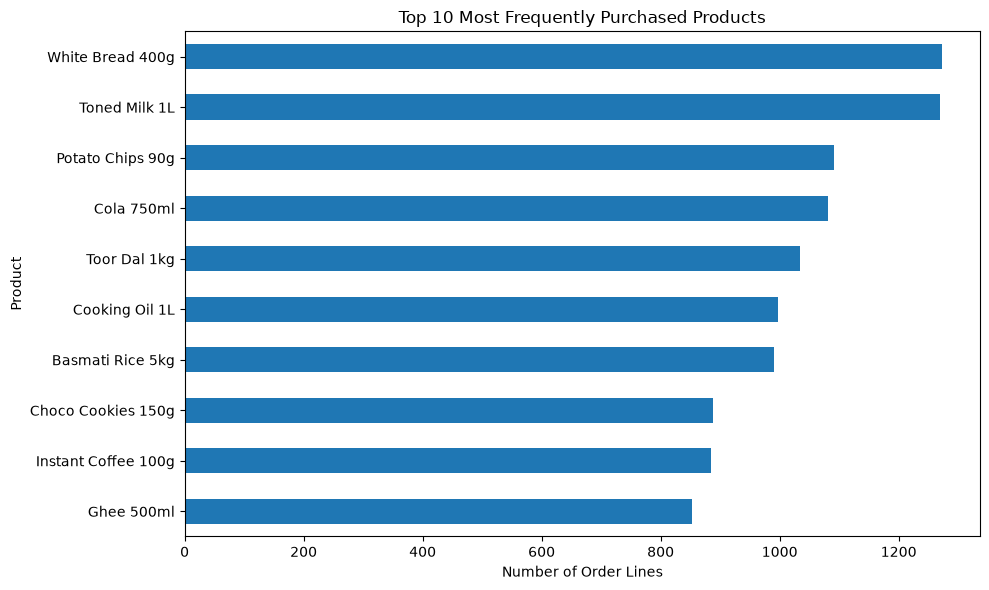

In [17]:
#Chart 1 — Top 10 most frequently purchased products

import matplotlib.pyplot as plt

top_products = tx["sku_name"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")
plt.title("Top 10 Most Frequently Purchased Products")
plt.xlabel("Number of Order Lines")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

#This chart shows which products appear most often in your transactions.


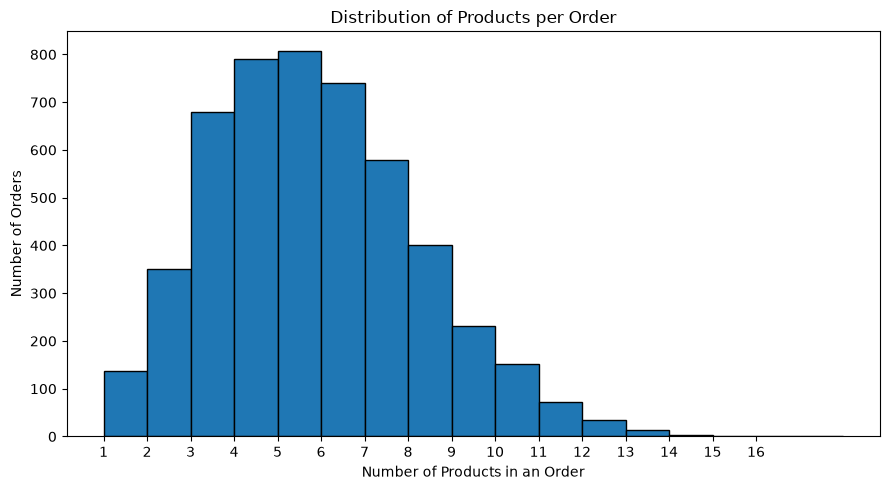

In [18]:
#Chart 2 — Distribution of basket sizes

plt.figure(figsize=(9, 5))
plt.hist(basket_sizes, bins=range(1, 19), edgecolor="black")
plt.title("Distribution of Products per Order")
plt.xlabel("Number of Products in an Order")
plt.ylabel("Number of Orders")
plt.xticks(range(1, 17))
plt.tight_layout()
plt.show()

#This visualises how many products customers typically purchase per order.


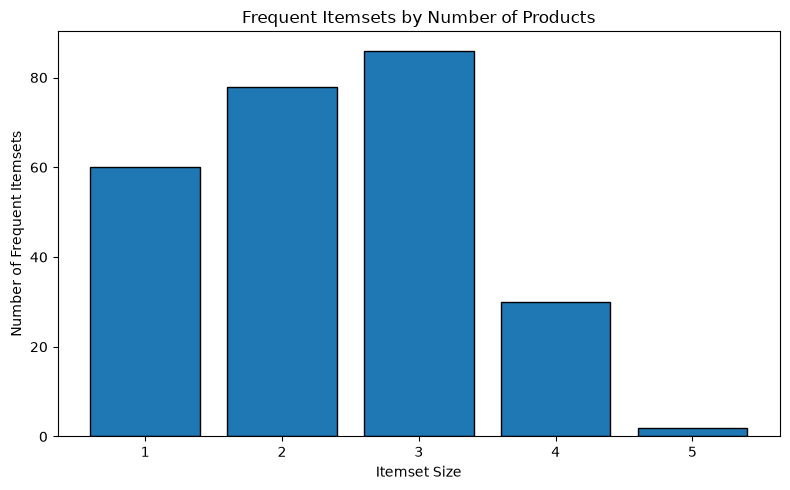

In [19]:
#Chart 3 — Frequent itemsets by size

itemset_sizes = frequent_itemsets["itemsets"].apply(len)
size_counts = itemset_sizes.value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(size_counts.index, size_counts.values, edgecolor="black")
plt.title("Frequent Itemsets by Number of Products")
plt.xlabel("Itemset Size")
plt.ylabel("Number of Frequent Itemsets")
plt.xticks(size_counts.index)
plt.tight_layout()
plt.show()


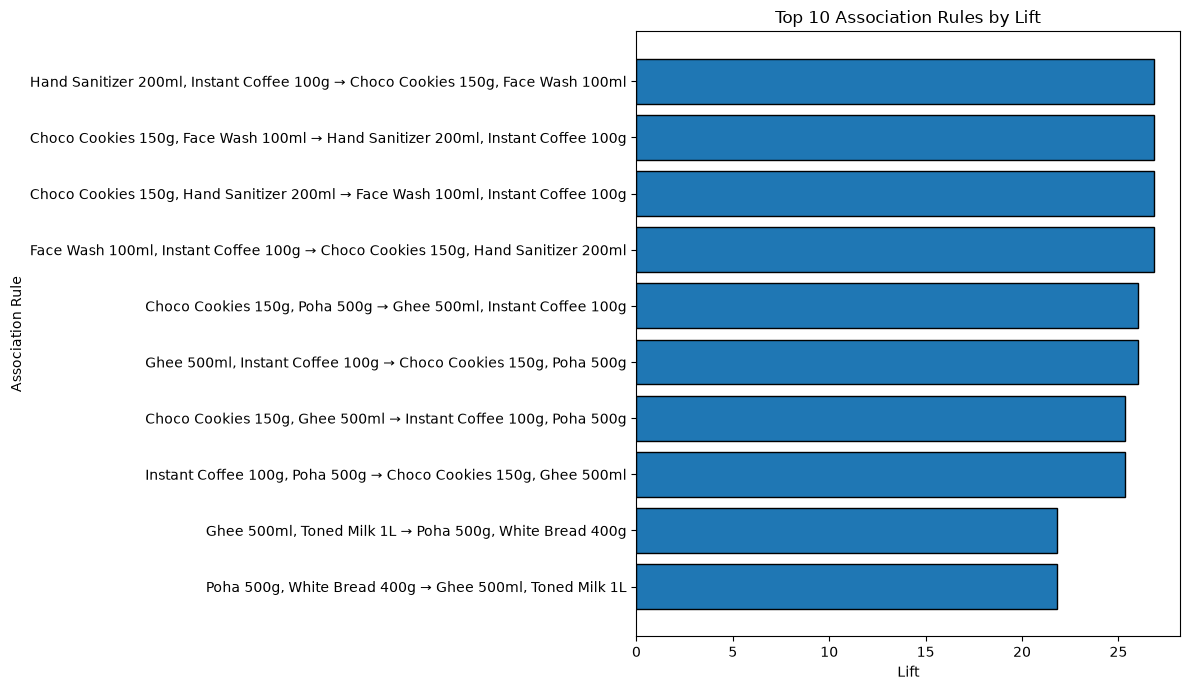

In [20]:
#Chart 4 — Top 10 association rules by lift

top10 = rules_all.nlargest(10, "lift").copy()

top10["rule"] = top10.apply(
    lambda row:
        ", ".join(sorted(row["antecedents"]))
        + " → "
        + ", ".join(sorted(row["consequents"])),
    axis=1
)

top10 = top10.sort_values("lift")

plt.figure(figsize=(12, 7))
plt.barh(top10["rule"], top10["lift"], edgecolor="black")
plt.title("Top 10 Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Association Rule")
plt.tight_layout()
plt.show()

#This highlights the strongest relative product associations. Remember that high lift alone doesn't necessarily make a rule the best business recommendation.

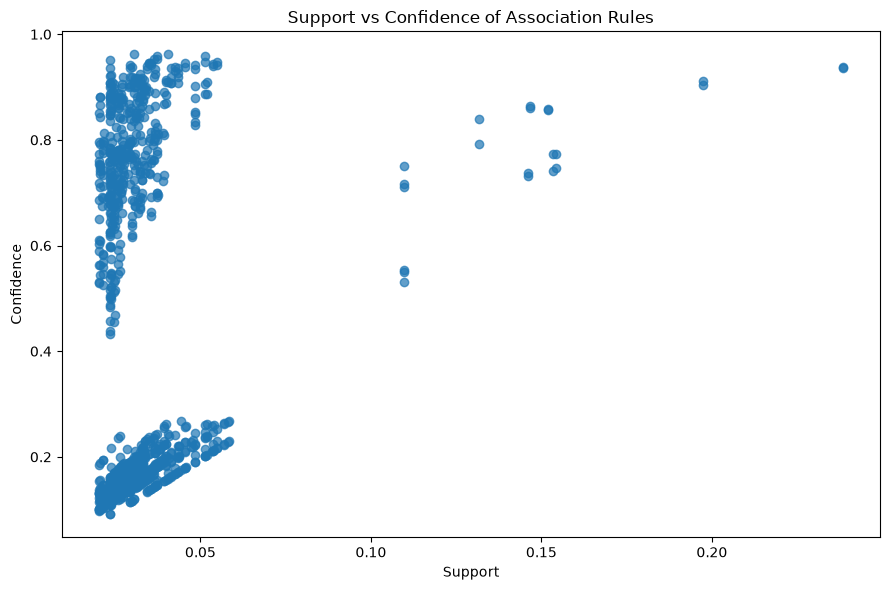

In [21]:
#Chart 5 — Support versus confidence

plt.figure(figsize=(9, 6))

plt.scatter(
    rules_all["support"],
    rules_all["confidence"],
    alpha=0.7
)

plt.title("Support vs Confidence of Association Rules")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()

#This helps to compare how frequently rules occur with how reliably the consequent follows the antecedent.


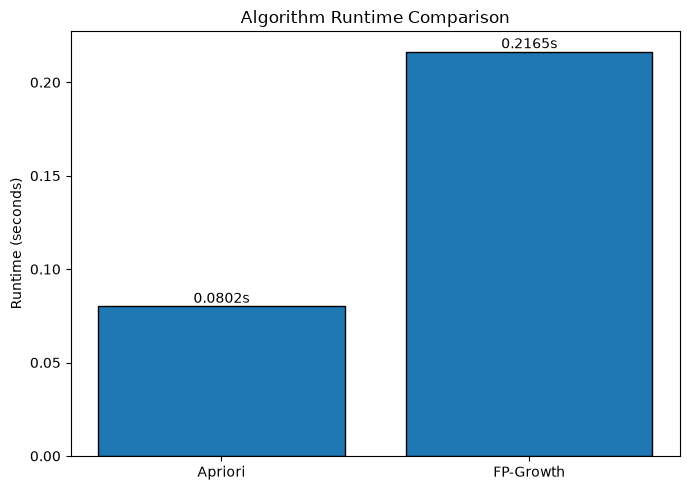

In [22]:
#Chart 6 — Apriori versus FP-Growth runtime

algorithms = ["Apriori", "FP-Growth"]
runtimes = [apriori_time, fp_time]

plt.figure(figsize=(7, 5))
plt.bar(algorithms, runtimes, edgecolor="black")
plt.title("Algorithm Runtime Comparison")
plt.ylabel("Runtime (seconds)")

for i, value in enumerate(runtimes):
    plt.text(i, value, f"{value:.4f}s", ha="center", va="bottom")

plt.tight_layout()
plt.show()


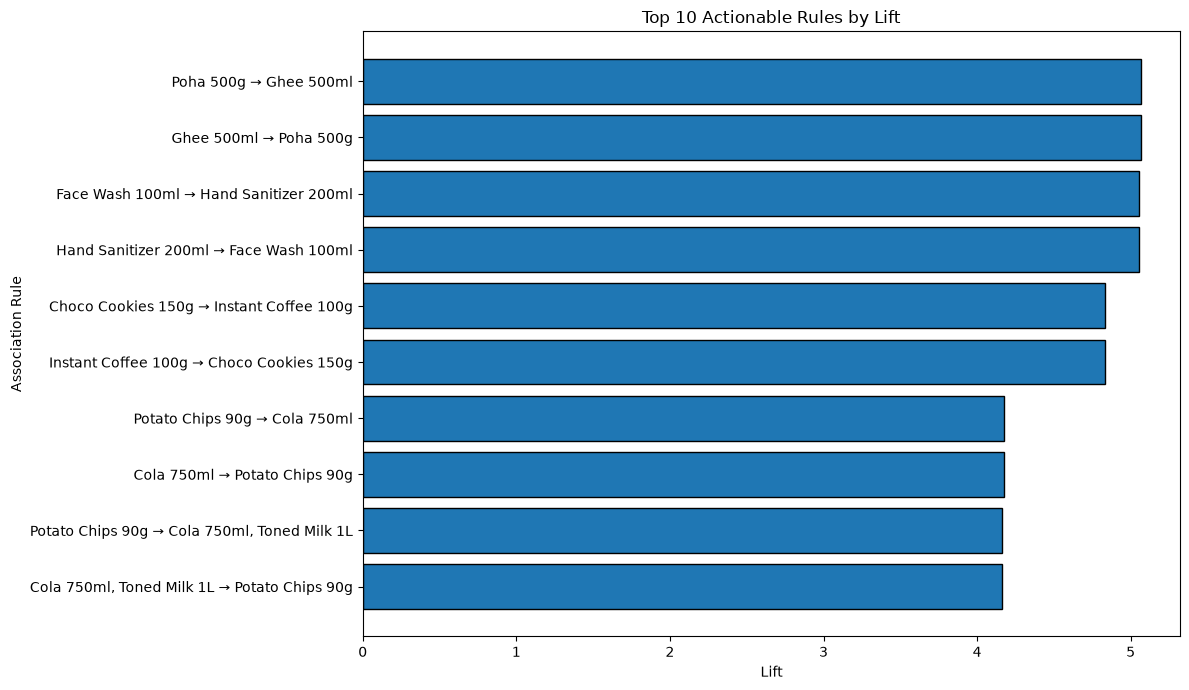

In [23]:
#Chart 7 — Top 10 actionable rules by lift

top_actionable = actionable.nlargest(10, "lift").copy()

top_actionable["rule"] = top_actionable.apply(
    lambda row:
        ", ".join(sorted(row["antecedents"]))
        + " → "
        + ", ".join(sorted(row["consequents"])),
    axis=1
)

top_actionable = top_actionable.sort_values("lift")

plt.figure(figsize=(12, 7))
plt.barh(
    top_actionable["rule"],
    top_actionable["lift"],
    edgecolor="black"
)
plt.title("Top 10 Actionable Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Association Rule")
plt.tight_layout()
plt.show()

#This chart focuses on rules that passed your support and lift thresholds and is useful for the business recommendations section.
